In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

#### READING THE DATASET 

In [161]:
df = pd.read_csv("pipeline_corrosion.csv")

In [134]:
df.shape

(8440, 48)

In [135]:
df.head()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0


In [136]:
df.tail()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
8435,SEG-0250,2022-06-25,19,10.48,X42,609.6,9.5,CTE,1,crude_oil,...,0.0838,0.058,0.745214,0.169667,-0.0725,4098.40,31510.77,4.22464,4002.8200,208.0
8436,SEG-0250,2023-02-17,20,11.13,X42,609.6,9.5,CTE,1,crude_oil,...,0.2251,-0.527,-6.721081,0.169233,0.1181,5041.14,36056.76,5.30400,4112.2325,237.0
8437,SEG-0250,2023-09-06,21,11.68,X42,609.6,9.5,CTE,1,crude_oil,...,0.1782,0.294,4.019688,0.147433,-0.1110,3582.78,35333.44,5.35602,4514.1200,201.0
8438,SEG-0250,2024-04-29,22,12.33,X42,609.6,9.5,CTE,1,crude_oil,...,0.1057,-0.453,-5.954259,0.187900,0.1143,4703.10,34608.60,6.38365,4622.5325,236.0
8439,SEG-0250,2024-11-21,23,12.89,X42,609.6,9.5,CTE,1,crude_oil,...,0.2238,0.222,3.102725,0.138600,-0.1512,4107.43,34214.70,4.97827,5033.0725,206.0


In [137]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   segment_id                    8440 non-null   object 
 1   measurement_date              8440 non-null   object 
 2   measurement_num               8440 non-null   int64  
 3   age_years                     8440 non-null   float64
 4   material                      8440 non-null   object 
 5   diameter_mm                   8440 non-null   float64
 6   nominal_thickness_mm          8440 non-null   float64
 7   coating_type                  8440 non-null   object 
 8   cathodic_protection           8440 non-null   int64  
 9   fluid_type                    8440 non-null   object 
 10  corrosion_mechanism           8440 non-null   object 
 11  seam_type                     8440 non-null   object 
 12  temperature_c                 8440 non-null   float64
 13  pre

In [138]:
df.describe()

,measurement_num,age_years,diameter_mm,nominal_thickness_mm,cathodic_protection,temperature_c,pressure_bar,flow_rate_m3h,pH,co2_partial_pressure_bar,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
count,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,8440.000000,...,7690.000000,8190.000000,8190.000000,8440.000000,8190.000000,8440.000000,8440.000000,8440.000000,8440.000000,8190.000000
mean,22.633649,16.801977,385.481671,10.105521,0.681754,69.417583,52.126742,247.503886,5.480473,2.544147,...,3.796439,-0.040497,0.066627,3.757358,-0.021472,3600.692977,13797.210873,3.789854,6316.725240,188.989255
std,16.567604,9.809462,205.075696,4.101488,0.465823,32.070074,28.562783,141.834829,1.117903,1.489995,...,8.451238,0.278374,14.930606,8.358461,1.725232,2686.115854,10711.262026,3.937311,3592.451361,119.231892
min,1.000000,0.000000,114.300000,2.810000,0.000000,5.000000,1.000000,1.000000,2.790000,0.000000,...,0.001000,-8.366000,-94.863363,0.001000,-24.966800,6.930000,0.000000,-5.113500,0.000000,60.000000
25%,9.000000,8.690000,219.100000,6.580000,0.000000,44.900000,29.200000,130.800000,4.610000,1.234750,...,0.006100,-0.124000,-1.914174,0.005858,-0.007200,1509.712500,5855.500000,0.648672,3338.192500,121.000000
50%,19.000000,16.530000,323.900000,9.760000,1.000000,67.200000,49.500000,244.000000,5.470000,2.524000,...,0.025200,-0.020000,-0.276258,0.025350,0.000000,2907.555000,10539.470000,2.760465,6209.250000,155.000000
75%,33.000000,24.332500,609.600000,12.530000,1.000000,94.600000,77.900000,370.050000,6.340000,3.946000,...,0.276725,0.077000,1.110299,0.284658,0.006800,5275.472500,20599.305000,6.294263,9064.846250,207.000000
max,82.000000,39.990000,762.000000,23.500000,1.000000,181.200000,109.900000,553.700000,8.160000,5.467000,...,25.015200,0.507000,169.000000,25.008700,24.803100,13381.760000,52219.200000,19.463400,14968.347500,746.000000


In [139]:
df.dtypes

segment_id                       object
measurement_date                 object
measurement_num                   int64
age_years                       float64
material                         object
diameter_mm                     float64
nominal_thickness_mm            float64
coating_type                     object
cathodic_protection               int64
fluid_type                       object
corrosion_mechanism              object
seam_type                        object
temperature_c                   float64
pressure_bar                    float64
flow_rate_m3h                   float64
pH                              float64
co2_partial_pressure_bar        float64
h2s_ppm                         float64
water_cut_pct                   float64
inhibitor_dose_ppm              float64
chloride_ppm                    float64
dissolved_o2_ppb                float64
coating_condition               float64
measured_thickness_mm           float64
corrosion_rate_mm_yr            float64


#### Exploratory Data Analysis (EDA)

In [140]:
df.columns

Index(['segment_id', 'measurement_date', 'measurement_num', 'age_years',
       'material', 'diameter_mm', 'nominal_thickness_mm', 'coating_type',
       'cathodic_protection', 'fluid_type', 'corrosion_mechanism', 'seam_type',
       'temperature_c', 'pressure_bar', 'flow_rate_m3h', 'pH',
       'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corrosion_rate_mm_yr',
       'cumulative_thickness_loss_mm', 'normalized_thickness',
       'remaining_useful_life_years', 'retirement_thickness_mm', 'alert_level',
       'month', 'year', 'quarter', 'thickness_lag_1', 'corr_rate_lag_1',
       'thickness_lag_2', 'corr_rate_lag_2', 'thickness_lag_3',
       'corr_rate_lag_3', 'thickness_change', 'thickness_change_pct',
       'corr_rate_rolling_3', 'corr_rate_acceleration',
       'temp_pressure_interaction', 'flow_watercut_interaction',
       'co2_ph_interaction', 'days

In [231]:
features = ['age_years','material','diameter_mm','nominal_thickness_mm','coating_type','cathodic_protection','fluid_type','corrosion_mechanism','seam_type','temperature_c',
'pressure_bar','flow_rate_m3h','pH','co2_partial_pressure_bar','h2s_ppm','water_cut_pct','inhibitor_dose_ppm','chloride_ppm','dissolved_o2_ppb','coating_condition','measured_thickness_mm',
'corr_rate_lag_1','thickness_lag_1', 'corr_rate_lag_2']

In [142]:
len(features)

24

In [232]:
X=df[features]

In [233]:
Y=df['corrosion_rate_mm_yr']

In [234]:
df1 = pd.concat([X, Y], axis=1)

In [220]:
numerical_columns =df1.select_dtypes(include=np.number).columns
catogorical_columns =df1.select_dtypes(include=['object', 'category']).columns

In [221]:
numerical_columns

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')

In [148]:
len(numerical_columns)

20

In [222]:
catogorical_columns 

Index(['material', 'coating_type', 'fluid_type', 'corrosion_mechanism',
       'seam_type'],
      dtype='object')

In [150]:
len(catogorical_columns )

5

In [223]:
df1.isnull().sum()

age_years                     0
material                      0
diameter_mm                   0
nominal_thickness_mm          0
coating_type                  0
cathodic_protection           0
fluid_type                    0
corrosion_mechanism           0
seam_type                     0
temperature_c                 0
pressure_bar                  0
flow_rate_m3h                 0
pH                            0
co2_partial_pressure_bar      0
h2s_ppm                       0
water_cut_pct                 0
inhibitor_dose_ppm            0
chloride_ppm                  0
dissolved_o2_ppb              0
coating_condition             0
measured_thickness_mm         0
corr_rate_lag_1             250
thickness_lag_1             250
corr_rate_lag_2             500
corrosion_rate_mm_yr          0
dtype: int64

In [235]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

                 Missing_Count  Missing_Percentage
corr_rate_lag_1            250            2.962085
thickness_lag_1            250            2.962085
corr_rate_lag_2            500            5.924171


In [225]:
df1.duplicated().sum()

np.int64(0)

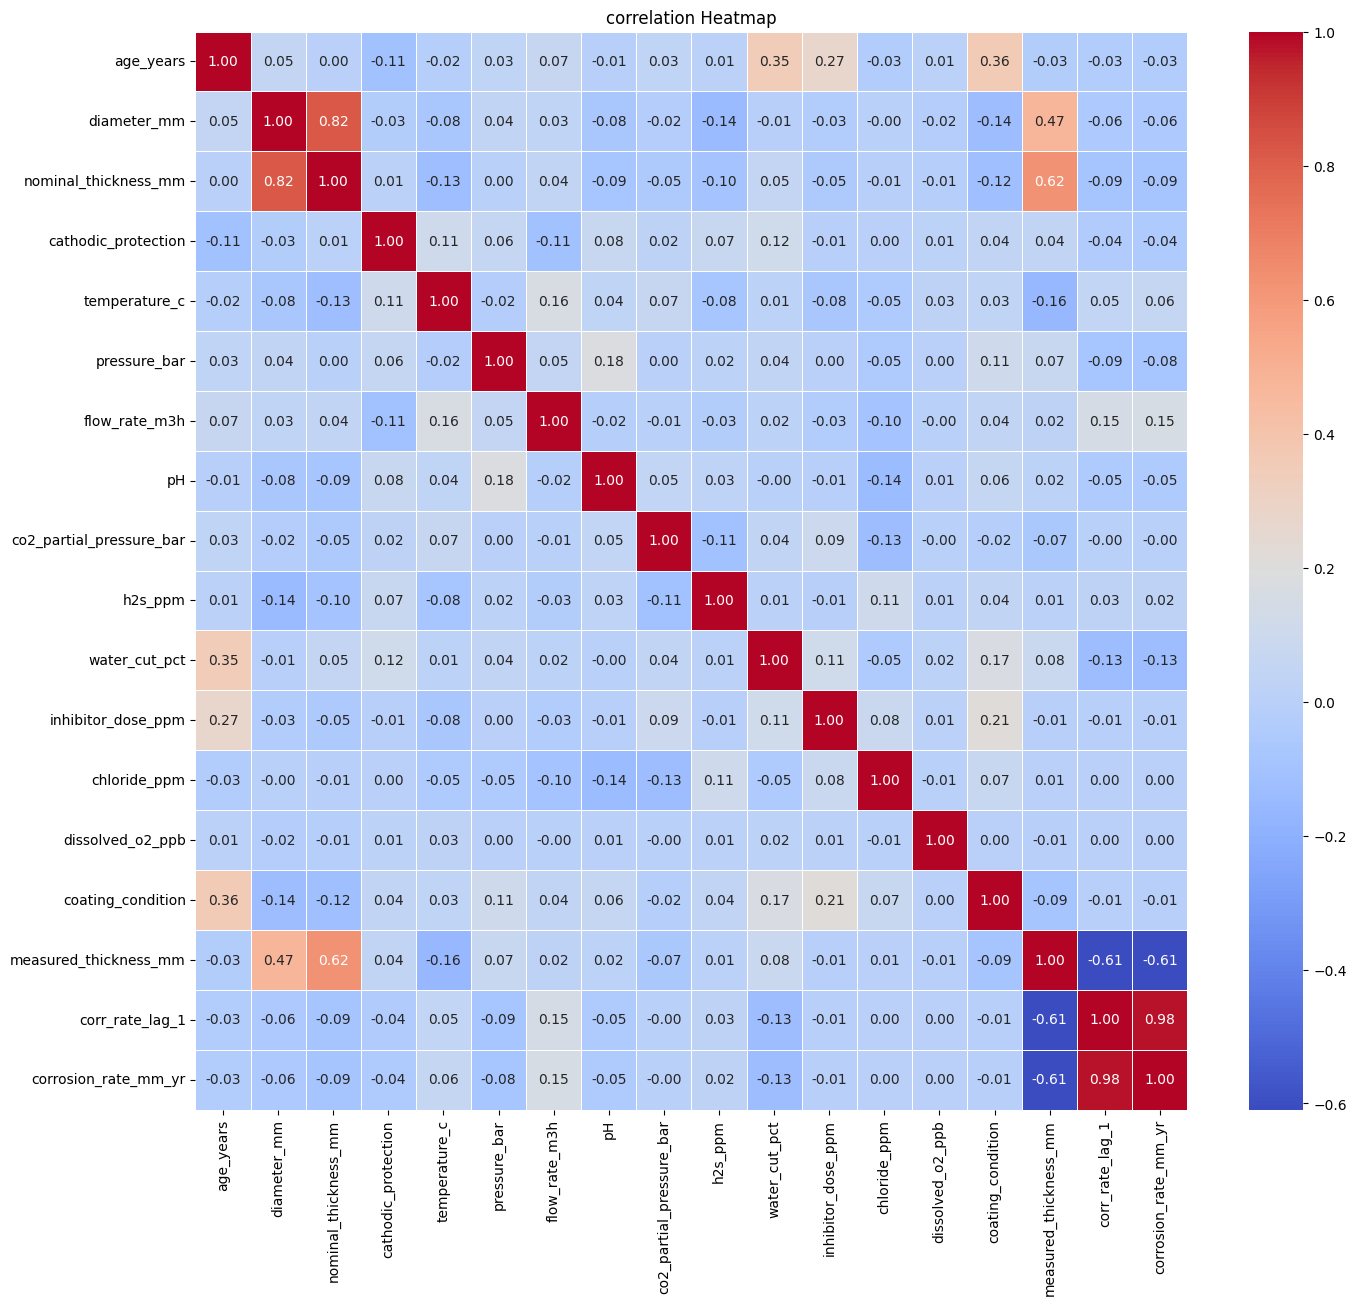

In [236]:
correlation=df1[numerical_columns].corr()
plt.figure(figsize=(16,14))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('correlation Heatmap')
plt.show()

In [237]:
df1=df1.drop('thickness_lag_1',axis=1)
df1=df1.drop('corr_rate_lag_2',axis=1)

In [238]:
df1=df1.drop('diameter_mm',axis=1)

In [239]:
numerical_columns =df1.select_dtypes(include=np.number).columns
catogorical_columns =df1.select_dtypes(include=['object', 'category']).columns

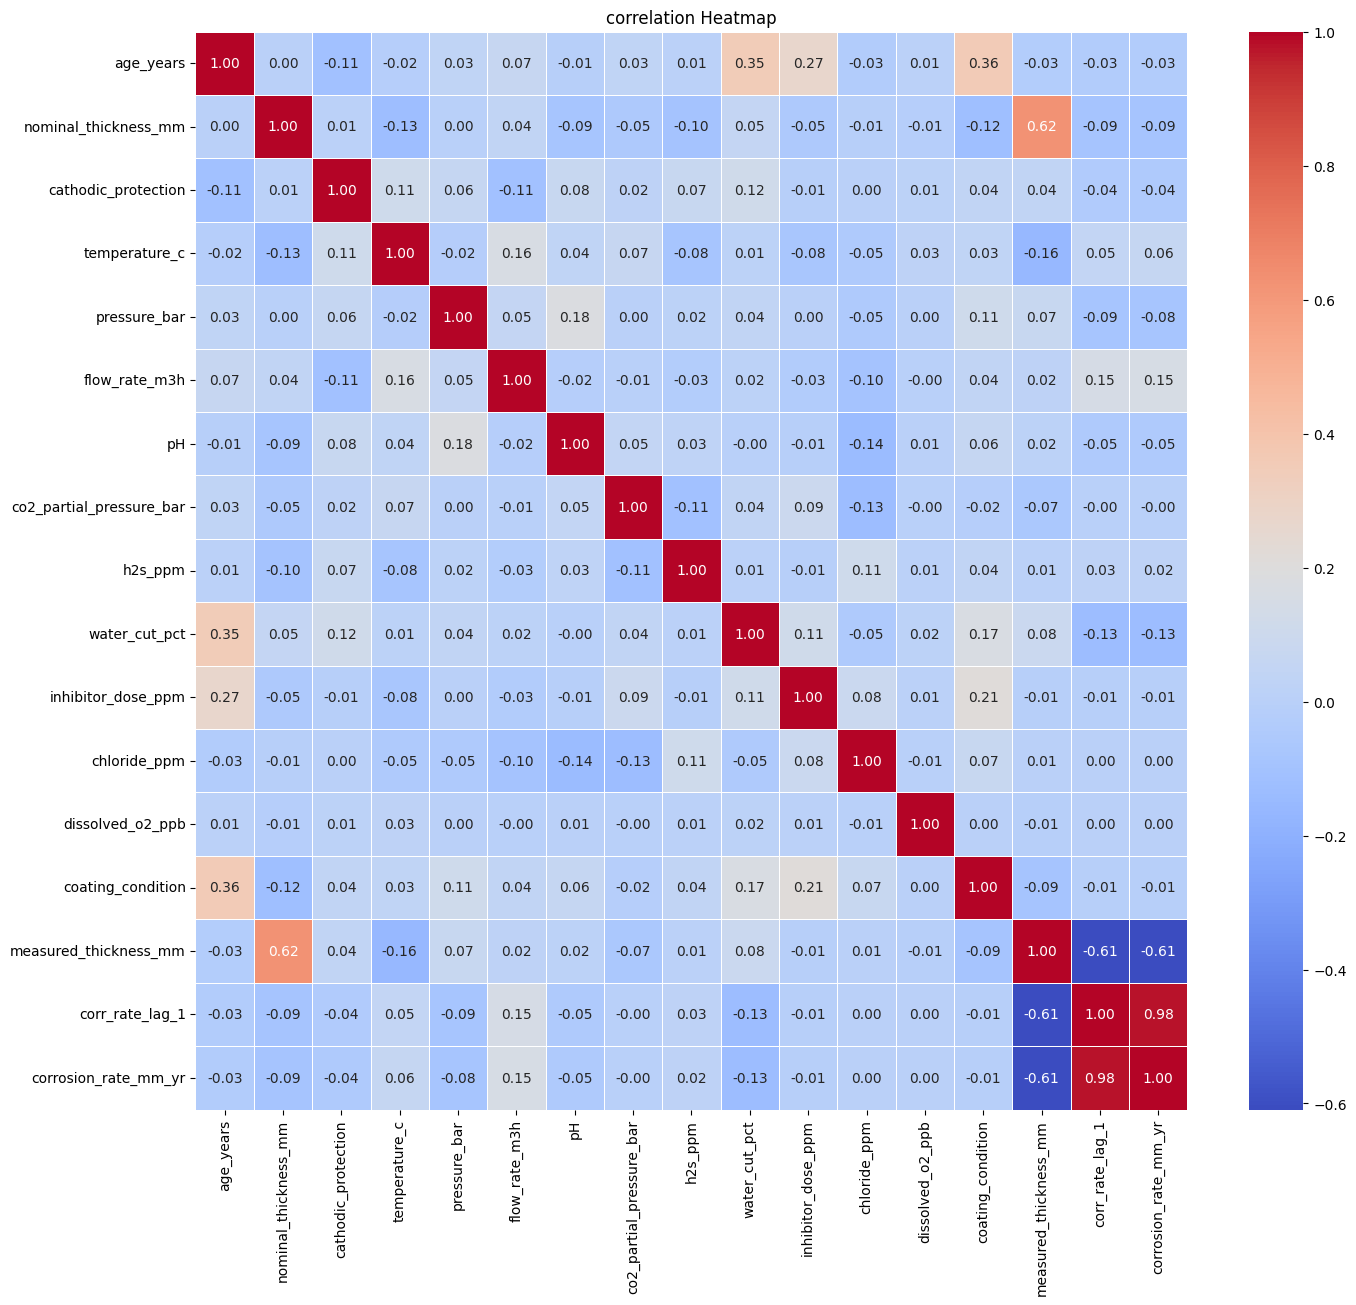

In [240]:
correlation=df1[numerical_columns].corr()
plt.figure(figsize=(16,14))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('correlation Heatmap')
plt.show()

In [197]:
df1.nunique()

age_years                   3280
material                       6
diameter_mm                    9
nominal_thickness_mm         225
coating_type                   4
cathodic_protection            2
fluid_type                     5
corrosion_mechanism            6
seam_type                      3
temperature_c               1369
pressure_bar                1028
flow_rate_m3h               4111
pH                           496
co2_partial_pressure_bar    4059
h2s_ppm                     4068
water_cut_pct                982
inhibitor_dose_ppm          2368
chloride_ppm                4122
dissolved_o2_ppb             590
coating_condition            571
measured_thickness_mm       5638
corr_rate_lag_1             2577
corrosion_rate_mm_yr        2615
dtype: int64

#### Droping the missing values

In [251]:
df1=df1.dropna()

In [252]:
df1.shape

(8190, 22)

In [253]:
df1.isnull().sum()

age_years                   0
material                    0
nominal_thickness_mm        0
coating_type                0
cathodic_protection         0
fluid_type                  0
corrosion_mechanism         0
seam_type                   0
temperature_c               0
pressure_bar                0
flow_rate_m3h               0
pH                          0
co2_partial_pressure_bar    0
h2s_ppm                     0
water_cut_pct               0
inhibitor_dose_ppm          0
chloride_ppm                0
dissolved_o2_ppb            0
coating_condition           0
measured_thickness_mm       0
corr_rate_lag_1             0
corrosion_rate_mm_yr        0
dtype: int64

#### Completed EDA

In [259]:
df1.to_csv('pipeline_corrosion_EDA_Completed.csv', index=False)